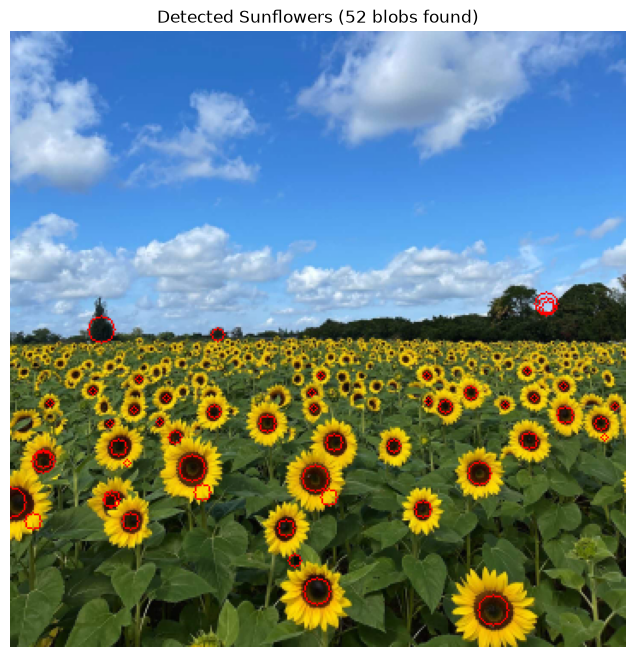

In [2]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the image as specified in the assignment[cite: 1]
im = cv.imread(
    'images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4
)

# Keep the original color image for drawing, and convert to grayscale for LoG detection
im_gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
im_float = im_gray.astype(np.float32) / 255.0

# Define sigma range
# min_sigma = 2.0
# max_sigma = 17.0
# num_sigmas = 18
# sigmas = np.linspace(min_sigma, max_sigma, num_sigmas)

sigmas = np.arange(2, 20)
# Initialize scale-space volume (H, W, num_sigmas)
h, w = im_float.shape
scale_space = np.zeros((h, w, len(sigmas)), dtype=np.float32)

# Build scale-space volume using scale-normalized Laplacian of Gaussian
for i, sigma in enumerate(sigmas):
    ksize = int(2 * np.ceil(3 * sigma) + 1)
    # Ensure kernel size is odd
    if ksize % 2 == 0:
        ksize += 1
    blurred = cv.GaussianBlur(im_float, (ksize, ksize), sigmaX=sigma, sigmaY=sigma)
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=3)
    scale_space[:, :, i] = (sigma**2) * np.abs(laplacian)

# Extract local maxima (blobs) across 3D scale-space (y, x, scale)
blobs = []
threshold = 0.7 * np.max(scale_space)  # Adjusted relative threshold
for i, sigma in enumerate(sigmas):
    slice_curr = scale_space[:, :, i]

    # Find local maxima in the 2D spatial plane using OpenCV morphology dilation
    ksize_morph = int(2 * round(2 * sigma) + 1)
    if ksize_morph % 2 == 0:
        ksize_morph += 1
    kernel = cv.getStructuringElement(cv.MORPH_RECT, (ksize_morph, ksize_morph))
    local_max_xy = cv.dilate(slice_curr, kernel)

    # Get neighboring scales for 3D scale-space comparison
    upper = (scale_space[:, :, i + 1] if i < len(sigmas) - 1 else np.zeros_like(slice_curr))
    lower = scale_space[:, :, i - 1] if i > 0 else np.zeros_like(slice_curr)

    is_max = (
        (slice_curr == local_max_xy)
        & (slice_curr >= upper)
        & (slice_curr >= lower)
        & (slice_curr > threshold)
    )

    y_idxs, x_idxs = np.nonzero(is_max)
    for y, x in zip(y_idxs, x_idxs):
        blobs.append((y, x, sigma))

# Draw circles on a copy of the original color image (OpenCV uses BGR natively)
output_img_bgr = im.copy()

for y, x, sigma in blobs:
    # Radius formula for LoG blob detection: r = sigma * sqrt(2)
    radius = int(sigma * np.sqrt(2))
    cv.circle(output_img_bgr, (x, y), radius, (0, 0, 255), 1)  # Yellow circle (BGR)

# Convert the final output image to RGB format as requested
output_img_rgb = cv.cvtColor(output_img_bgr, cv.COLOR_BGR2RGB)

# Display using matplotlib
plt.figure(figsize=(12, 8))
plt.imshow(output_img_rgb)
plt.axis('off')
plt.title(f'Detected Sunflowers ({len(blobs)} blobs found)')
plt.show()

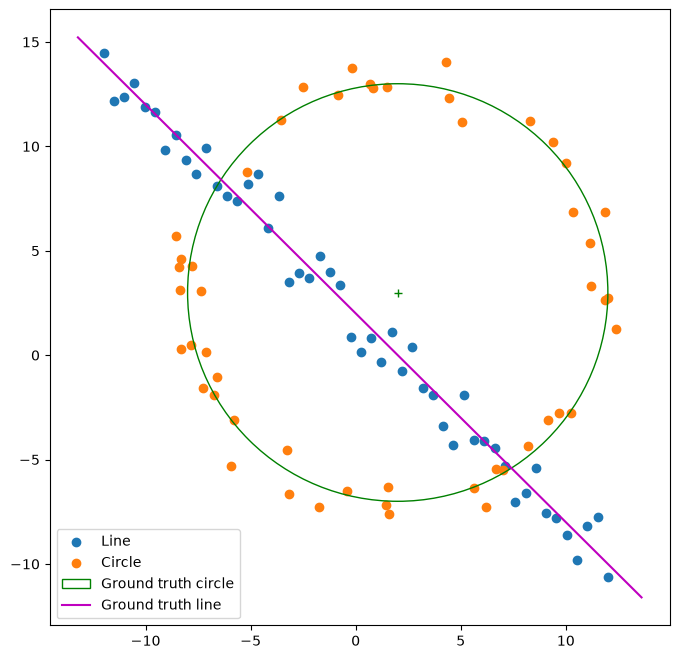

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

# np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))  # All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.show()

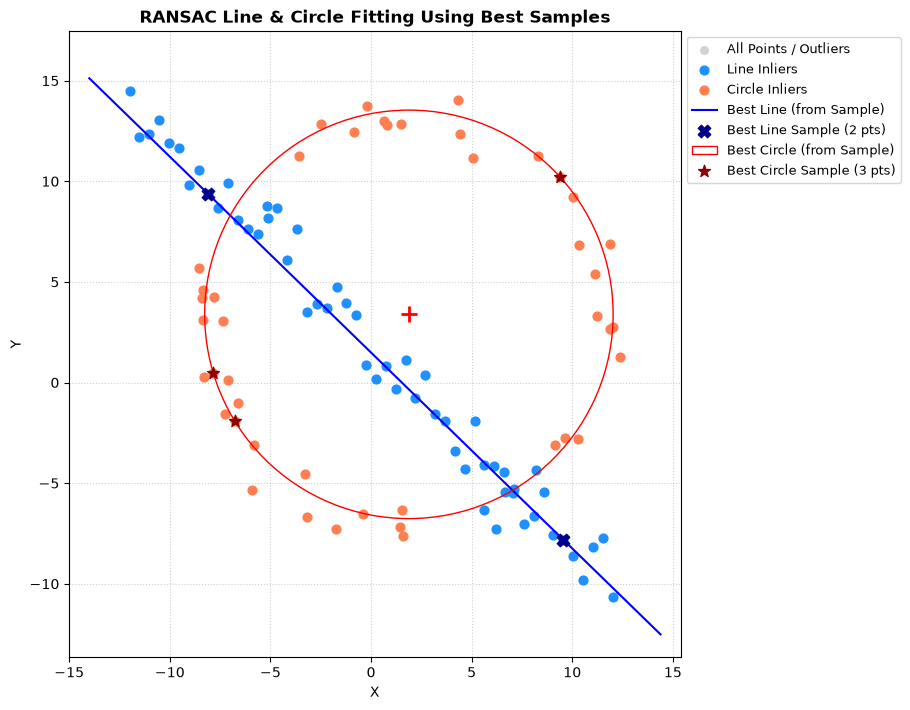

In [ ]:
def ransac_line(X, num_iterations=1000, threshold=2.0, min_inliers=25):
    best_a, best_b, best_d = None, None, None
    best_inliers = []
    best_sample = None
    max_inliers_count = 0
    N_points = X.shape[0]
    
    for _ in range(num_iterations):
        sample_indices = np.random.choice(N_points, 2, replace=False)
        p1 = X[sample_indices[0]]
        p2 = X[sample_indices[1]]
        
        dir_vec = p2 - p1
        normal = np.array([-dir_vec[1], dir_vec[0]])
        norm_val = np.linalg.norm(normal)
        if norm_val < 1e-9:
            continue
        normal = normal / norm_val
        a, b = normal[0], normal[1]
        d = a * p1[0] + b * p1[1]
        
        distances = np.abs(np.dot(X, np.array([a, b])) - d)
        inlier_indices = np.where(distances < threshold)[0]
        
        if len(inlier_indices) > max_inliers_count:
            max_inliers_count = len(inlier_indices)
            best_inliers = inlier_indices
            best_a, best_b, best_d = a, b, d
            best_sample = (p1, p2, a, b, d)
            
    return best_a, best_b, best_d, best_inliers, best_sample

# --- 3. Circle Fitting Functions (RANSAC using Best Sample) ---
def fit_circle_3points(p1, p2, p3):
    A_mat = np.array([
        [p1[0], p1[1], 1],
        [p2[0], p2[1], 1],
        [p3[0], p3[1], 1]
    ])
    b_mat = -np.array([
        p1[0]**2 + p1[1]**2,
        p2[0]**2 + p2[1]**2,
        p3[0]**2 + p3[1]**2
    ])
    try:
        params = np.linalg.solve(A_mat, b_mat)
    except np.linalg.LinAlgError:
        return None, None, None
    
    A, B, C = params
    x0 = -A / 2.0
    y0 = -B / 2.0
    r_sq = x0**2 + y0**2 - C
    if r_sq < 0:
        return None, None, None
    r = np.sqrt(r_sq)
    return x0, y0, r

def ransac_circle(X, num_iterations=1000, threshold=2.0, min_inliers=25):
    best_x0, best_y0, best_r = None, None, None
    best_inliers = []
    best_sample = None
    max_inliers_count = 0
    N_points = X.shape[0]
    
    if N_points < 3:
        return None, None, None, [], None
        
    for _ in range(num_iterations):
        sample_indices = np.random.choice(N_points, 3, replace=False)
        p1, p2, p3 = X[sample_indices[0]], X[sample_indices[1]], X[sample_indices[2]]
        
        x0, y0, r = fit_circle_3points(p1, p2, p3)
        if x0 is None:
            continue
            
        distances = np.abs(np.sqrt((X[:, 0] - x0)**2 + (X[:, 1] - y0)**2) - r)
        inlier_indices = np.where(distances < threshold)[0]
        
        if len(inlier_indices) > max_inliers_count:
            max_inliers_count = len(inlier_indices)
            best_inliers = inlier_indices
            best_x0, best_y0, best_r = x0, y0, r
            best_sample = (p1, p2, p3, x0, y0, r)
            
    return best_x0, best_y0, best_r, best_inliers, best_sample

# --- 4. Execution ---
line_threshold = 1.6
circle_threshold = 1.8
a_est, b_est, d_est, line_inliers, line_sample = ransac_line(X, 1000, threshold)

# Remove line inliers to isolate circle points
line_mask = np.zeros(X.shape[0], dtype=bool)
line_mask[line_inliers] = True
X_remaining = X[~line_mask]

x0_est, y0_est, r_est, circle_inliers_rel, circle_sample = ransac_circle(X_remaining, 1000, threshold)

# Map circle inliers back to indices of original X array
remaining_indices = np.where(~line_mask)[0]
circle_inliers = remaining_indices[circle_inliers_rel]

# --- 5. Visualization ---
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Plot all points
ax.scatter(X[:, 0], X[:, 1], color='lightgray', s=30, label='All Points / Outliers', zorder=1)

# Plot line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], color='dodgerblue', s=40, label='Line Inliers', zorder=2)

# Plot circle inliers
ax.scatter(X[circle_inliers, 0], X[circle_inliers, 1], color='coral', s=40, label='Circle Inliers', zorder=2)

# Plot Best Line (from Sample)
x_vals = np.array([X[:, 0].min() - 2, X[:, 0].max() + 2])
y_vals = (d_est - a_est * x_vals) / b_est

ax.plot(x_vals, y_vals, color='blue', label='Best Line (from Sample)', zorder=3)

# Plot Line Initial Sample Hypothesis & Sample Points
if line_sample:
    p1_l, p2_l, a_init, b_init, d_init = line_sample
    ax.scatter([p1_l[0], p2_l[0]], [p1_l[1], p2_l[1]], color='darkblue', s=80, marker='X', zorder=5, label='Best Line Sample (2 pts)')

# Plot Best Circle (from Sample)
best_circle_patch = plt.Circle((x0_est, y0_est), r_est, color='red', fill=False, label='Best Circle (from Sample)', zorder=3)
ax.add_patch(best_circle_patch)
ax.plot(x0_est, y0_est, 'r+', markersize=12, markeredgewidth=2, zorder=4)

# Plot Circle Initial Sample Hypothesis & Sample Points
if circle_sample:
    p1_c, p2_c, p3_c, x0_init, y0_init, r_init = circle_sample
    sample_pts_c = np.array([p1_c, p2_c, p3_c])
    ax.scatter(sample_pts_c[:, 0], sample_pts_c[:, 1], color='darkred', s=80, marker='*', zorder=5, label='Best Circle Sample (3 pts)')


ax.set_xlim(X[:, 0].min() - 3, X[:, 0].max() + 3)
ax.set_ylim(X[:, 1].min() - 3, X[:, 1].max() + 3)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
plt.title("RANSAC Line & Circle Fitting Using Best Samples", fontsize=12, fontweight='bold')
plt.xlabel("X")
plt.ylabel("Y")
plt.tight_layout()
plt.show()